# Conformal pillbox longitudinal impedance with `SolverFIT3D_FD`

This notebook is a first frequency-domain validation of the new WAKIS FIT solver.

It uses the same pillbox STL geometry as the existing `007` / conformal validation
examples, but runs only one deliberately coarse conformal case:

- `geometry_mode="conformal"`
- `stl_method="voxelize_rectilinear"`
- `conformal_pec_snap_fraction=0.2`
- vacuum cavity
- PEC shell
- PEC background
- PEC outer boundaries
- target resolution: \(N_\mathrm{pWl}=15\) at \(f_\mathrm{max}=1\,\mathrm{GHz}\)

The longitudinal impedance is obtained directly in the frequency domain from

\[
\left(
    M_\sigma
    + j\omega M_\varepsilon
    + \frac{1}{j\omega} C^T M_\nu C
\right)e
= -\hat j .
\]

The phasor convention is \(e^{+j\omega t}\). For a relativistic beam travelling
in \(+z\),

\[
\hat j_z(z) = I_0 e^{-jkz},
\qquad
Z_\parallel(\omega)
=
-\frac{1}{I_0}
\sum_z e_z(z)e^{+jkz}.
\]

Since the unknown \(e_z\) is already the electric grid voltage
\(\int E_z\,dz\), no additional `dz` factor is used in the impedance sum.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv
from scipy.constants import c as c_light
from scipy.signal import find_peaks
from scipy.sparse.linalg import spsolve

from wakis import GridFIT3D
from wakis.field import Field

# Works whether SolverFIT3D_FD has already been exported in wakis/__init__.py or not.
try:
    from wakis import SolverFIT3D_FD
except ImportError:
    from wakis.solverFIT3D_FD import SolverFIT3D_FD

## Geometry and mesh

The mesh spacing is derived from the shortest vacuum wavelength represented in
the sweep,

\[
h_\mathrm{target}=\frac{c/f_\mathrm{max}}{N_\mathrm{pWl}}.
\]

`Nx`, `Ny`, and `Nz` are rounded upward independently, so the actually obtained
worst-direction \(N_\mathrm{pWl}\) can be slightly larger than 15.


In [23]:
# ---------------------------------------------------------------------------
# Pillbox STL geometry
# ---------------------------------------------------------------------------

cavity_path = Path("../tests/stl/007_vacuum_cavity.stl")
shell_path = Path("../tests/stl/007_lossymetal_shell.stl")

if not cavity_path.exists() or not shell_path.exists():
    raise FileNotFoundError(
        "Pillbox STL files not found. Run this notebook from the WAKIS "
        "notebooks directory."
    )

stl_solids = {
    "cavity": str(cavity_path),
    "shell": str(shell_path),
}

stl_materials = {
    "cavity": "vacuum",
    "shell": "pec",
}

stl_material_types = {
    "cavity": "normal",
    "shell": "pec",
}

solids = pv.read(cavity_path) + pv.read(shell_path)
xmin, xmax, ymin, ymax, zmin, zmax = solids.bounds

Lx = xmax - xmin
Ly = ymax - ymin
Lz = zmax - zmin

# ---------------------------------------------------------------------------
# Frequency range and mesh resolution
# ---------------------------------------------------------------------------

FMIN = 1.0e6
FMAX = 1.0e9
N_FREQ = 10

NPWL = 15
CONFORMAL_ETA = 0.2

wavelength_min = c_light / FMAX
target_h = wavelength_min / NPWL

Nx = max(1, int(np.ceil(Lx / target_h)))
Ny = max(1, int(np.ceil(Ly / target_h)))
Nz = max(1, int(np.ceil(Lz / target_h)))

dx = Lx / Nx
dy = Ly / Ny
dz = Lz / Nz

actual_npwl = wavelength_min / max(dx, dy, dz)

# Same physical exclusion fraction as skip_cells=5 for Nz=60.
skip_cells = max(1, int(np.round(Nz * 5.0 / 60.0)))

print("Geometry bounds:")
print(f"  x: [{xmin:.6g}, {xmax:.6g}] m")
print(f"  y: [{ymin:.6g}, {ymax:.6g}] m")
print(f"  z: [{zmin:.6g}, {zmax:.6g}] m")
print()
print(f"Requested NpWl : {NPWL}")
print(f"Actual NpWl    : {actual_npwl:.3f}")
print(f"Grid           : {Nx} x {Ny} x {Nz}")
print(f"dx,dy,dz [mm]  : {dx * 1e3:.3f}, {dy * 1e3:.3f}, {dz * 1e3:.3f}")
print(f"skip_cells     : {skip_cells}")

Geometry bounds:
  x: [-0.26, 0.26] m
  y: [-0.26, 0.26] m
  z: [-0.25, 0.55] m

Requested NpWl : 15
Actual NpWl    : 15.364
Grid           : 27 x 27 x 41
dx,dy,dz [mm]  : 19.259, 19.259, 19.512
skip_cells     : 3


## Build the conformal grid and FD solver

For this first test all six outer boundaries are PEC. The conformal cavity is
represented as a vacuum STL region inside a PEC shell/background.

The new FD solver is expected to build `free_E_idx`, `Meps`, `Mnu`, `Msigma`
and `SL` during initialization.


In [24]:
grid = GridFIT3D(
    xmin,
    xmax,
    ymin,
    ymax,
    zmin,
    zmax,
    Nx,
    Ny,
    Nz,
    stl_solids=stl_solids,
    stl_materials=stl_materials,
    stl_material_types=stl_material_types,
    stl_method="voxelize_rectilinear",
    geometry_mode="conformal",
    bg_material_type="pec",
    conformal_pec_snap_fraction=CONFORMAL_ETA,
    subpixel_smoothing=False,
    stl_scale=1.0,
    stl_rotate=[0.0, 0.0, 0.0],
    stl_translate=[0.0, 0.0, 0.0],
    verbose=1,
)

bc_low = ["pec", "pec", "pec"]
bc_high = ["pec", "pec", "pec"]

solver = SolverFIT3D_FD(
    grid,
    bc_low=bc_low,
    bc_high=bc_high,
    use_stl=True,
    bg="pec",
    dtype=np.float64,
    use_gpu=False,
    verbose=1,
)

print()
print("FD operator dimensions:")
print(f"  full E space : {3 * solver.N}")
print(f"  active E DOFs: {len(solver.free_E_idx)}")
print(f"  C_red        : {solver.C_red.shape}")
print(f"  Mnu          : {solver.Mnu.shape}")
print(f"  Meps         : {solver.Meps.shape}")
print(f"  Msigma       : {solver.Msigma.shape}")
print(f"  SL           : {solver.SL.shape}")

Generating grid with 29889 mesh cells...
Importing STL solids...
 * Marking grid points inside STL solid 'cavity'...
    * STL solid cavity: 7240 primal points, 6765 cell centers, and 7072 dual points marked inside the solid.
 * Marking grid points inside STL solid 'shell'...
    * STL solid shell: 3512 primal points, 2596 cell centers, and 3810 dual points marked inside the solid.
    * primal x-edges: 2452 geometric hits, 2452 crossings, 0 contacts, 0 with multiple crossing positions
    * primal y-edges: 2452 geometric hits, 2452 crossings, 0 contacts, 0 with multiple crossing positions
    * primal z-edges: 1952 geometric hits, 1952 crossings, 0 contacts, 0 with multiple crossing positions
    * dual x-edges: 2391 geometric hits, 2391 crossings, 0 contacts, 0 with multiple crossing positions
    * dual y-edges: 2395 geometric hits, 2395 crossings, 0 contacts, 0 with multiple crossing positions
    * dual z-edges: 1907 geometric hits, 1907 crossings, 0 contacts, 0 with multiple cros

## Beam line and frequency sweep

The source and test trajectory are both on axis. The source amplitude is
\(I_0=1\,\mathrm{A}\), so the final impedance normalization is especially simple.

The source vector represents the **integrated current through the dual faces**,
not a current density in \(\mathrm{A/m^2}\). Therefore the z-directed source
entries are set directly to \(I_0 e^{-jkz}\).

The first and last few longitudinal cells are excluded, matching the physical
exclusion fraction used in the earlier pillbox wake examples.


In [25]:
xs = 0.0
ys = 0.0
xt = 0.0
yt = 0.0

beta = 1.0
beam_velocity = beta * c_light
I0 = 1.0

ixs = np.abs(solver.x - xs).argmin()
iys = np.abs(solver.y - ys).argmin()

ixt = np.abs(solver.x - xt).argmin()
iyt = np.abs(solver.y - yt).argmin()

if 2 * skip_cells >= solver.Nz:
    raise ValueError(
        f"skip_cells={skip_cells} leaves no longitudinal integration interval."
    )

z_slice = slice(None)
z_path = solver.z

print(f"Source position: x={solver.x[ixs]:.6g} m, y={solver.y[iys]:.6g} m")
print(f"Test position:   x={solver.x[ixt]:.6g} m, y={solver.y[iyt]:.6g} m")
print(
    f"Active z interval: {z_path[0]:.6g} ... {z_path[-1]:.6g} m ({len(z_path)} samples)"
)

source = Field(
    solver.Nx,
    solver.Ny,
    solver.Nz,
    dtype=np.complex128,
)

e_grid = Field(
    solver.Nx,
    solver.Ny,
    solver.Nz,
    dtype=np.complex128,
)

# Check once that the chosen beam-source DOFs are active.
source.fromarray(
    np.zeros(
        3 * solver.N,
        dtype=np.complex128,
    )
)
source[ixs, iys, z_slice, "z"] = 1.0

beam_source_idx = np.flatnonzero(np.abs(source.toarray()) > 0.0)

active_lookup = np.zeros(
    3 * solver.N,
    dtype=bool,
)
active_lookup[solver.free_E_idx] = True

inactive_beam_dofs = beam_source_idx[~active_lookup[beam_source_idx]]

if inactive_beam_dofs.size:
    raise RuntimeError(
        f"{inactive_beam_dofs.size} beam-source DOFs are inactive. "
        "Check the source trajectory, PEC geometry and boundary handling."
    )

print("All beam-source DOFs are active.")

Source position: x=0 m, y=0 m
Test position:   x=0 m, y=0 m
Active z interval: -0.240244 ... 0.540244 m (41 samples)
All beam-source DOFs are active.


In [26]:
f_list = np.linspace(
    FMIN,
    # FMAX,
    1e8,
    N_FREQ,
)

Z_long = np.zeros(
    len(f_list),
    dtype=np.complex128,
)

for i, f in enumerate(f_list):
    omega = 2.0 * np.pi * f
    k = omega / beam_velocity

    # ---------------------------------------------------------------
    # Integrated beam-current source:
    #
    # e^(+j omega t) convention and propagation in +z
    # -> exp(-j k z)
    # ---------------------------------------------------------------

    source.fromarray(
        np.zeros(
            3 * solver.N,
            dtype=np.complex128,
        )
    )

    source[
        ixs,
        iys,
        z_slice,
        "z",
    ] = I0 * np.exp(-1j * k * z_path)

    source_red = source.toarray()[solver.free_E_idx]

    # ---------------------------------------------------------------
    # Solve:
    #
    # A(omega) e = -j_hat
    # ---------------------------------------------------------------

    A = solver.build_system_matrix(omega)

    e_red = spsolve(
        A,
        -source_red,
    )

    e_full = np.zeros(
        3 * solver.N,
        dtype=np.complex128,
    )

    e_full[solver.free_E_idx] = e_red

    e_grid.fromarray(e_full)

    # ---------------------------------------------------------------
    # Longitudinal impedance:
    #
    # Z_parallel = -(1/I0) sum e_z exp(+j k z)
    #
    # e_z already contains the line integral E_z dl.
    # ---------------------------------------------------------------

    test_phase = np.exp(1j * k * z_path)

    Z_long[i] = (
        -e_grid[
            ixt,
            iyt,
            z_slice,
            "z",
        ]
        @ test_phase
        / I0
    )

    if i == 0 or i == len(f_list) - 1 or (i + 1) % 20 == 0:
        print(
            f"{i + 1:4d}/{len(f_list)}: "
            f"f={f / 1e9:.4f} GHz, "
            f"|Z|={abs(Z_long[i]):.6e} Ohm"
        )

   1/10: f=0.0010 GHz, |Z|=2.830153e-01 Ohm
  10/10: f=0.1000 GHz, |Z|=2.871313e+01 Ohm


## Longitudinal impedance

For an ideal lossless PEC cavity the exact frequency-domain response has poles at
the eigenfrequencies. Consequently the peak amplitudes depend strongly on the
sampled frequency grid and can become extremely large close to a resonance.
For this first validation the resonance **positions and overall structure** are
therefore more informative than the absolute peak height.


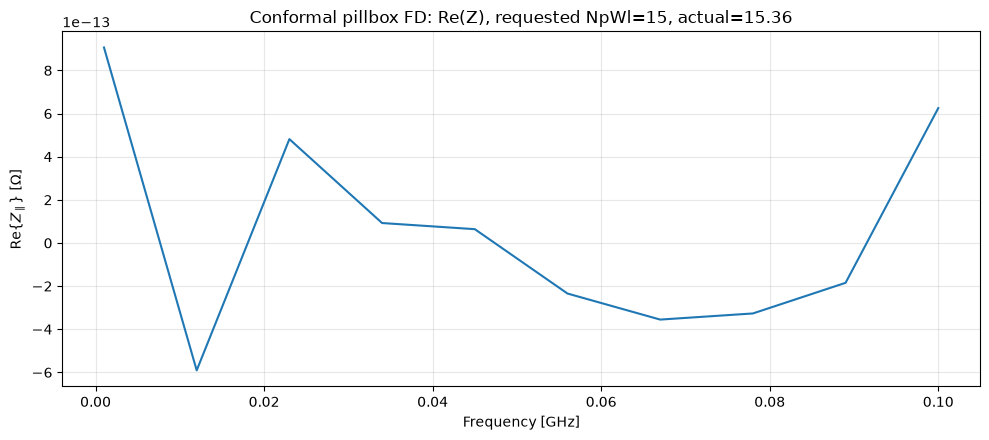

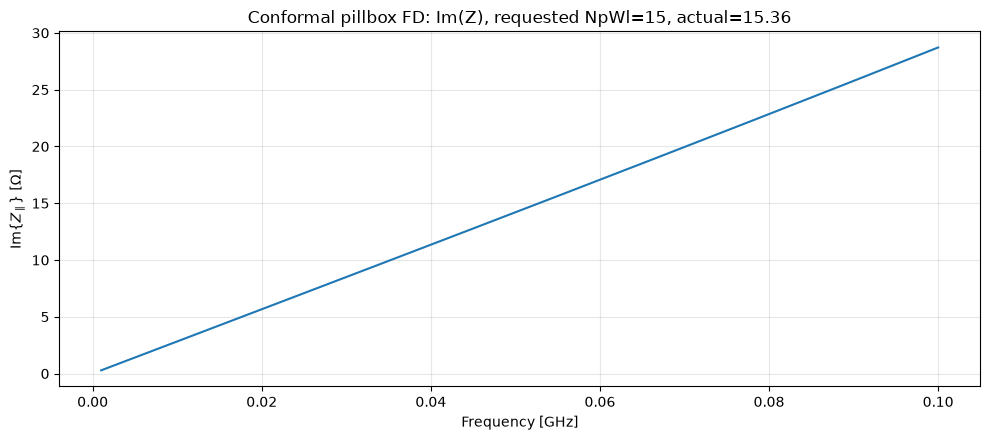

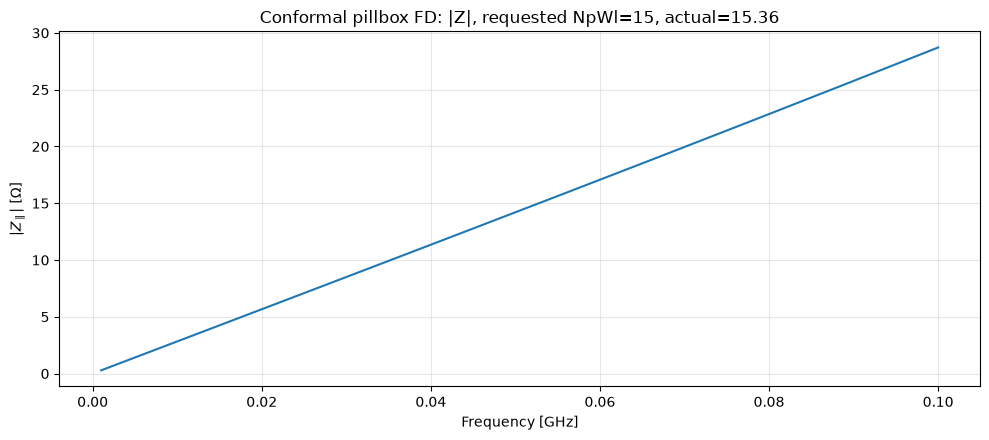

In [27]:
plt.figure(figsize=(10, 4.5))
plt.plot(
    f_list / 1e9,
    Z_long.real,
)
plt.xlabel("Frequency [GHz]")
plt.ylabel(r"$\mathrm{Re}\{Z_\parallel\}$ [$\Omega$]")
plt.title(
    f"Conformal pillbox FD: Re(Z), requested NpWl={NPWL}, actual={actual_npwl:.2f}"
)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 4.5))
plt.plot(
    f_list / 1e9,
    Z_long.imag,
)
plt.xlabel("Frequency [GHz]")
plt.ylabel(r"$\mathrm{Im}\{Z_\parallel\}$ [$\Omega$]")
plt.title(
    f"Conformal pillbox FD: Im(Z), requested NpWl={NPWL}, actual={actual_npwl:.2f}"
)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


plt.figure(figsize=(10, 4.5))
plt.plot(
    f_list / 1e9,
    np.abs(Z_long),
)
plt.xlabel("Frequency [GHz]")
plt.ylabel(r"$|Z_\parallel|$ [$\Omega$]")
plt.title(f"Conformal pillbox FD: |Z|, requested NpWl={NPWL}, actual={actual_npwl:.2f}")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Simple resonance diagnostic

This is intentionally only a quick diagnostic for the first FD run. It reports
local maxima of \(|Z_\parallel|\) on the sampled frequency grid; it is not a
high-accuracy resonance extraction.


In [ ]:
Z_abs = np.abs(Z_long)

finite = np.isfinite(Z_abs)

if not np.any(finite):
    raise RuntimeError("No finite impedance samples were obtained.")

prominence = 0.02 * np.nanmax(Z_abs[finite])

peak_idx, properties = find_peaks(
    Z_abs,
    prominence=prominence,
)

print("Detected impedance peaks:")
print("-------------------------")

if len(peak_idx) == 0:
    print("No peaks found with the current frequency sampling/prominence.")
else:
    for n, idx in enumerate(peak_idx, start=1):
        print(f"{n:2d}: f = {f_list[idx] / 1e6:10.3f} MHz, |Z| = {Z_abs[idx]:.6e} Ohm")

## Notes for the next validation step

Once this smoke test behaves as expected, the most useful follow-up is a direct
comparison against the existing TD/WakeSolver pillbox result on the **same
conformal mesh**. For resonance amplitudes, a controlled loss model or another
regularization will eventually be needed because the present PEC cavity is
lossless.
